# Single-cell ATAC-seq part 2: topic modelling with pycisTopic

**Case study: Can liver cell types and hepatocyte zonation be recovered from chromatin accessibility alone?**

Bravo González-Blas C, et al. *Single-cell spatial multi-omics and deep learning dissect enhancer-driven gene regulatory networks in liver zonation.* Nature Cell Biology (2024). https://doi.org/10.1038/s41556-023-01316-4

**Research questions:**

1. Can the cell types of the liver be recovered from accessibility alone, without RNA?
2. Is hepatocyte zonation (periportal versus pericentral) visible in the chromatin?
3. Which regions differ between pericentral and periportal hepatocytes, and are they near known zonated genes?

This notebook looks at questions 1 and 2 with topic modelling.

## Introduction

A cell × peak matrix from scATAC-seq is too sparse to compare cells region by region. [pycisTopic](https://pycistopic.readthedocs.io/) (Bravo González-Blas et al., *Nature Methods* 2019; *Nature Methods* 2023) solves this with **topic modelling**, a technique from text mining:

| text mining | scATAC-seq |
|---|---|
| document | cell |
| word | region (peak) |
| topic: words that tend to occur together | **topic: regions that tend to be accessible together** |

The model (Latent Dirichlet Allocation, LDA) describes every cell as a mixture of topics (**cell-topic** matrix), and every topic as a distribution over regions (**topic-region** matrix). Some topics are shared by all cells (e.g. housekeeping promoters), others are specific to a cell type or state (e.g. hepatocyte enhancers, or pericentral hepatocyte enhancers). The cell-topic matrix is a compact, denoised description of each cell, used for clustering and UMAP; the topic-region matrix tells us *which* regions define each cell state.

In this notebook we:

1. build a cisTopic object from the fragments, using the cells and consensus peaks of [part 1](part_1_qc_preprocessing.ipynb);
2. train topic models and select the number of topics;
3. correct the batch effect between the two samples (Harmony), cluster cells and visualise them with UMAP;
4. explore the topics: which topics belong to which cell type, and which follow hepatocyte zonation.

Differentially accessible regions with pycisTopic come in [part 4](part_4_dars.ipynb).

## Step 0: Setup

This notebook uses the `atac-sc` environment and the "Python (atac-sc)" kernel; see [part 1](part_1_qc_preprocessing.ipynb) for how to install them. Input data are in the folder `data` next to this notebook, our results go to `data/results/part_2`.

In [1]:
%matplotlib inline
import os
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

os.environ["PYTHONWARNINGS"] = "ignore"  # also silences the parallel workers
warnings.filterwarnings("ignore")

from pycisTopic.cistopic_class import create_cistopic_object_from_fragments, merge
from pycisTopic.lda_models import run_cgs_models_mallet, evaluate_models
from pycisTopic.clust_vis import find_clusters, run_umap, plot_metadata, plot_topic, cell_topic_heatmap, harmony
from pycisTopic.topic_binarization import binarize_topics

plt.rcParams["figure.dpi"] = 80

# The folder of this notebook (the kernel starts there). Kept when you run this cell again after os.chdir below.
HERE = globals().get("HERE", os.getcwd())

# Input data and software, in the folder data next to this notebook
SC = f"{HERE}/data"
GENOME = f"{SC}/genome"
MALLET = f"{SC}/software/Mallet-202108/bin/mallet"

# Your own results
OUT = f"{SC}/results/part_2"
os.makedirs(OUT, exist_ok=True)
os.chdir(OUT)

# results of part 1 (yours if you ran it, otherwise the pre-generated ones)
PART1 = f"{SC}/results/part_1"
if not os.path.exists(f"{PART1}/cells.tsv"):
    PART1 = f"{SC}/data_generated"
print("part 1 results:", os.path.relpath(PART1, HERE))

N_CPU = 4
FRAGMENTS = {"Mouse_4_10x": f"{SC}/fragments/Mouse_4_10x.fragments.tsv.gz",
             "Mouse_5_NST": f"{SC}/fragments/Mouse_5_NST.fragments.tsv.gz"}

part 1 results: data/data_generated


## Step 1: Building the cisTopic object

We start from the selected cells and the consensus peaks of [part 1](part_1_qc_preprocessing.ipynb). pycisTopic counts the fragments of each cell in each region; we give it the list of valid barcodes per sample so it only reads those cells. In the merged object, a cell is named `barcode___sample`. This takes about 5 minutes.

In [2]:
import builtins
original_print = builtins.print  # pycisTopic's parallel backend (Ray) replaces print, which later breaks UMAP

cells = pd.read_csv(f"{PART1}/cells.tsv", sep="\t", index_col=0)
print(cells.groupby("sample").size())

objects = []
for sample, fragments in FRAGMENTS.items():
    obj = create_cistopic_object_from_fragments(
        path_to_fragments=fragments,
        path_to_regions=f"{PART1}/consensus_peaks.bed",
        path_to_blacklist=f"{GENOME}/mm10-blacklist.v2.bed",
        valid_bc=cells.index[cells["sample"] == sample].tolist(),
        n_cpu=N_CPU,
        project=sample,
    )
    objects.append(obj)
cistopic_obj = merge(objects)
builtins.print = original_print
print(cistopic_obj)

sample
Mouse_4_10x    7301
Mouse_5_NST    3996
dtype: int64
2026-10-28 02:21:34,047 cisTopic     INFO     Reading data for Mouse_4_10x
2026-10-28 02:23:36,202 cisTopic     INFO     valid_bc provided, selecting barcodes!
2026-10-28 02:23:43,784 cisTopic     INFO     Counting number of unique fragments (Unique_nr_frag)
2026-10-28 02:23:57,271 cisTopic     INFO     Counting fragments in regions
2026-10-28 02:24:29,858 cisTopic     INFO     Creating fragment matrix
2026-10-28 02:24:54,470 cisTopic     INFO     Converting fragment matrix to sparse matrix
2026-10-28 02:25:00,068 cisTopic     INFO     Removing blacklisted regions
2026-10-28 02:25:00,495 cisTopic     INFO     Creating CistopicObject
2026-10-28 02:25:01,507 cisTopic     INFO     Done!
2026-10-28 02:25:01,551 cisTopic     INFO     Reading data for Mouse_5_NST
2026-10-28 02:25:37,756 cisTopic     INFO     valid_bc provided, selecting barcodes!
2026-10-28 02:25:39,941 cisTopic     INFO     Counting number of unique fragments (Uniq

2026-10-28 02:23:57,309	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html
2026-10-28 02:24:01,832	INFO worker.py:2033 -- Started a local Ray instance.
2026-10-28 02:25:48,699	INFO worker.py:2033 -- Started a local Ray instance.


The object stores the fragment counts (`fragment_matrix`), a binary accessibility matrix (`binary_matrix`) used by the topic model, and per-cell and per-region tables (`cell_data`, `region_data`). We add the annotations of part 1 to `cell_data`:

In [3]:
annotation = cells.copy()
annotation.index = annotation.index + "___" + annotation["sample"]
annotation["zone"] = annotation["zone"].fillna("")
cistopic_obj.add_cell_data(annotation[["sample", "cell_type", "zone"]].rename(columns={"sample": "mouse"}))
cistopic_obj.cell_data[["mouse", "cell_type", "zone", "cisTopic_nr_frag", "cisTopic_nr_acc"]].head()

,mouse,cell_type,zone,cisTopic_nr_frag,cisTopic_nr_acc
GGCTCAATCGATTCTT-1___Mouse_4_10x,Mouse_4_10x,Hepatocyte,PP,11134,10069
GTAAGCGCATGCTCCC-1___Mouse_4_10x,Mouse_4_10x,Hepatocyte,mid,11034,9945
GGCAATCGTTGGTTAG-1___Mouse_4_10x,Mouse_4_10x,Hepatocyte,PP,5582,5263
GTGGCTTCAGTAGGAT-1___Mouse_4_10x,Mouse_4_10x,HSC,,3125,2935
AATGCATGTGGTTAGC-1___Mouse_4_10x,Mouse_4_10x,HSC,,19685,15039


## Step 2: Topic modelling

pycisTopic trains LDA models with [Mallet](https://mimno.github.io/Mallet/), a fast Java implementation using collapsed Gibbs sampling. The number of topics is a parameter: too few topics merge distinct cell states, too many split them into noise. The usual approach is to train models with different numbers of topics and compare them.

Training takes long: about an hour for a few models on this dataset. **We load pre-computed models** (10 to 50 topics, 500 iterations; trained with `scripts/12_topic_models.sh`). If you want to train one yourself, set `TRAIN = True`; a single small model takes about 15 minutes.

In [4]:
TRAIN = False

if TRAIN:
    os.environ["MALLET_MEMORY"] = "16G"  # memory for the Java process
    os.makedirs("mallet_tmp", exist_ok=True)
    # n_topics: one model per number of topics; n_iter: Gibbs sampling iterations (500 for the real models)
    # alpha, eta: priors of the cell-topic and topic-region distributions (pycisTopic's defaults)
    models = run_cgs_models_mallet(
        cistopic_obj, n_topics=[10], n_cpu=N_CPU, n_iter=150, random_state=555,
        alpha=50, alpha_by_topic=True, eta=0.1, eta_by_topic=False,
        tmp_path="mallet_tmp", save_path=None, mallet_path=MALLET)
else:
    with open(f"{SC}/data_generated/topic_models.pkl", "rb") as f:
        models = pickle.load(f)
print([m.n_topic for m in models])

[10, 20, 30, 40, 50]


### Choosing the number of topics

`evaluate_models` scores each model with several metrics. For scATAC data the most useful are the **log-likelihood** in the last iteration (how well the model fits the data; it keeps increasing slowly with more topics) and the **topic coherence** of Mimno et al. (2011) (whether the top regions of a topic really co-occur in cells). Pick the model where the metrics level off: more topics beyond that point add little.

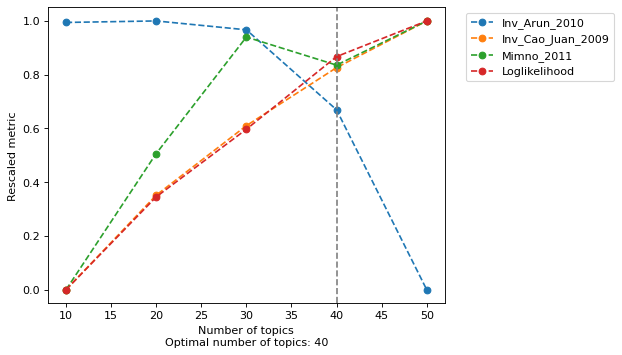

In [5]:
model = evaluate_models(models, select_model=None, return_model=False, plot_metrics=False)
plt.show()

The metrics rarely agree perfectly. Here the log-likelihood still increases up to 50 topics, the coherence (Mimno) is high from 30 topics on, and the Arun metric drops sharply after 40. `evaluate_models` combines them and suggests **40 topics** (dashed line). Models with 30 to 50 topics would all give a similar picture of the main cell types; we take 40.

In [6]:
N_TOPICS = 40
model = evaluate_models(models, select_model=N_TOPICS, return_model=True, plot=False)
cistopic_obj.add_LDA_model(model)
print(f"model with {model.n_topic} topics added")

model with 40 topics added


## Step 3: Batch correction, UMAP and clustering

The cell-topic matrix (topics × cells) is the low-dimensional representation of the data. From here on, the workflow is the same as for single-cell RNA-seq: a nearest-neighbour graph, UMAP and Leiden clustering, with topics instead of principal components. The [single-nucleus RNA-seq practical](../single-nucleus-rna-seq/Regulatory_genomics_example_single_nucleus_RNA_seq_of_the_mouse_liver.ipynb) explains these steps in detail (neighbour graph, UMAP, Leiden resolution, library effects); here we focus on what is specific to ATAC.

A UMAP on the cell-topic matrix shows the structure. Colour it by sample and by cell type: do cells group by cell type, or also by sample?

2026-10-28 02:26:26,954 cisTopic     INFO     Running UMAP


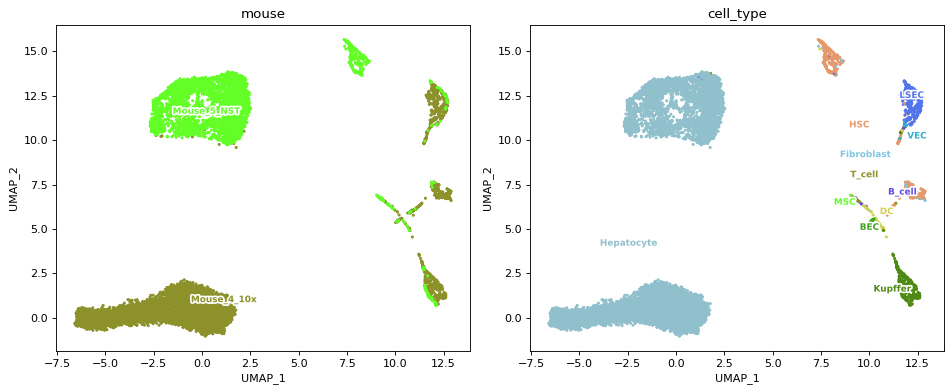

In [7]:
# UMAP on the cell-topic matrix (scale=True: z-score every topic first)
run_umap(cistopic_obj, target="cell", scale=True, reduction_name="UMAP")
plot_metadata(cistopic_obj, reduction_name="UMAP", variables=["mouse", "cell_type"],
              num_columns=2, figsize=(12, 5), dot_size=3, text_size=8)
plt.show()

The hepatocytes of the two mice form two completely separate groups, and the other cell types are split by mouse within their cluster: a strong **batch effect** from the different nuclei isolation protocols. [Harmony](https://github.com/immunogenomics/harmony) (Korsunsky et al., 2019) corrects the cell-topic coordinates so that cells of different batches mix, while keeping the biological differences. Batch correction should be applied with care. Harmony adjusts the coordinates so that every cluster contains cells from all batches. This works best when the batches contain the same cell types in similar proportions. A cell type present in only one batch usually stays separate (the Harmony paper shows this with cell lines), but large differences in composition can lead to over-correction, so always compare the corrected and the uncorrected embedding. Here each mouse was processed with a different protocol, so Harmony also removes any real difference between the two mice.

2026-10-28 02:26:51,306 harmonypy    INFO     Computing initial centroids with sklearn.KMeans...
2026-10-28 02:26:53,184 harmonypy    INFO     sklearn.KMeans initialization complete.
2026-10-28 02:26:53,209 harmonypy    INFO     Iteration 1 of 10
2026-10-28 02:26:54,437 harmonypy    INFO     Iteration 2 of 10
2026-10-28 02:26:55,694 harmonypy    INFO     Iteration 3 of 10
2026-10-28 02:26:57,027 harmonypy    INFO     Iteration 4 of 10
2026-10-28 02:26:58,367 harmonypy    INFO     Converged after 4 iterations
2026-10-28 02:26:58,432 cisTopic     INFO     Running UMAP


2026-10-28 02:26:51,306 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 02:26:53,184 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 02:26:53,209 - harmonypy - INFO - Iteration 1 of 10
2026-10-28 02:26:54,437 - harmonypy - INFO - Iteration 2 of 10
2026-10-28 02:26:55,694 - harmonypy - INFO - Iteration 3 of 10
2026-10-28 02:26:57,027 - harmonypy - INFO - Iteration 4 of 10
2026-10-28 02:26:58,367 - harmonypy - INFO - Converged after 4 iterations


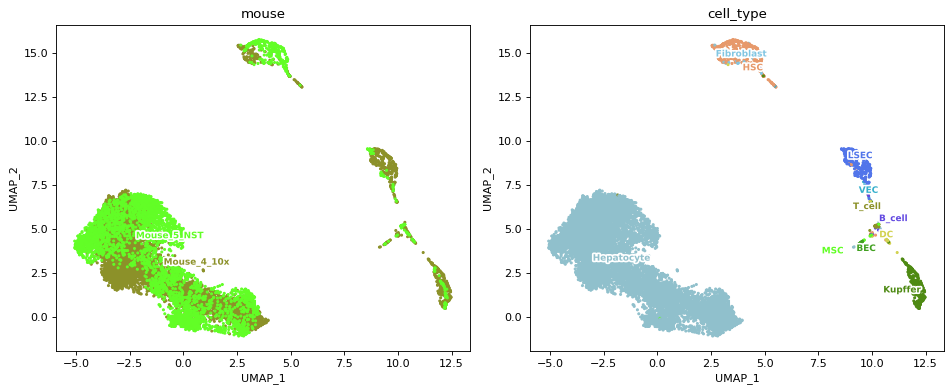

In [8]:
# vars_use: the batch variable(s) to correct for; the corrected coordinates are used with harmony=True below
harmony(cistopic_obj, vars_use=["mouse"], scale=True, random_state=555)
run_umap(cistopic_obj, target="cell", scale=True, harmony=True, reduction_name="UMAP_harmony")
plot_metadata(cistopic_obj, reduction_name="UMAP_harmony", variables=["mouse", "cell_type"],
              num_columns=2, figsize=(12, 5), dot_size=3, text_size=8)
plt.show()

Now we cluster the cells with the Leiden algorithm on a k-nearest-neighbour graph of the (Harmony-corrected) topics, at two resolutions. Higher resolution gives more, smaller clusters.

2026-10-28 02:27:04,431 cisTopic     INFO     Finding neighbours


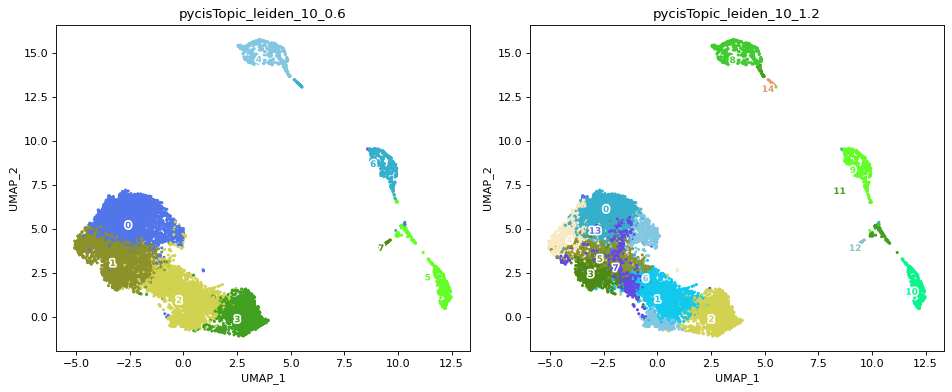

In [9]:
# k: neighbours in the graph; res: Leiden resolutions; harmony=True: use the corrected topics
find_clusters(cistopic_obj, target="cell", k=10, res=[0.6, 1.2], prefix="pycisTopic_", scale=True, harmony=True)
plot_metadata(cistopic_obj, reduction_name="UMAP_harmony",
              variables=["pycisTopic_leiden_10_0.6", "pycisTopic_leiden_10_1.2"],
              num_columns=2, figsize=(12, 5), dot_size=3, text_size=8)
plt.show()

How well do the clusters, found from ATAC alone, match the RNA-based cell types? A contingency table shows which cell types end up in which cluster; the **adjusted Rand index** (ARI) summarises the agreement in one number (1 = identical partitions, 0 = random).

In [10]:
cd = cistopic_obj.cell_data  # short name for the per-cell table
# ARI between the RNA cell types and the clusters; crosstab: number of cells per cell type (rows) and cluster (columns)
print("ARI resolution 0.6:", round(adjusted_rand_score(cd["cell_type"], cd["pycisTopic_leiden_10_0.6"]), 2))
print("ARI resolution 1.2:", round(adjusted_rand_score(cd["cell_type"], cd["pycisTopic_leiden_10_1.2"]), 2))
pd.crosstab(cd["cell_type"], cd["pycisTopic_leiden_10_0.6"])

ARI resolution 0.6: 0.14
ARI resolution 1.2: 0.07


pycisTopic_leiden_10_0.6,0,1,2,3,4,5,6,7
cell_type,,,,,,,,
BEC,0,0,0,0,0,0,0,44
B_cell,0,0,0,0,0,10,1,0
DC,0,0,0,0,1,34,0,0
Fibroblast,0,0,0,0,14,0,0,0
HSC,0,0,0,0,475,19,32,0
Hepatocyte,3185,2587,2474,1629,5,7,1,1
Kupffer,1,0,0,0,1,349,0,0
LSEC,3,0,0,0,2,1,350,0
MSC,1,0,1,0,0,4,0,2


Every major non-parenchymal cell type ends up in its own cluster (HSC, LSEC, Kupffer, BEC). The rare types join a related cluster: the immune cells (T cells, B cells, DC) the Kupffer cluster, fibroblasts the HSC cluster and VEC the LSEC cluster. Yet the ARI is low (0.14). The reason: hepatocytes, almost 90% of the cells, are split over four clusters at resolution 0.6, and the ARI counts every pair of hepatocytes in different clusters as a disagreement. At a higher resolution the split gets finer and the ARI lower. Is the split noise, or biology? Colour the UMAP by **zone**:

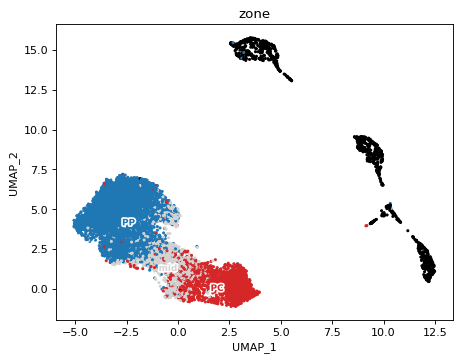

In [11]:
plot_metadata(cistopic_obj, reduction_name="UMAP_harmony", variables=["zone"], dot_size=3, text_size=8,
              color_dictionary={"zone": {"PP": "tab:blue", "mid": "lightgrey", "PC": "tab:red", "": "black"}})
plt.show()

The hepatocyte clusters follow zonation: periportal hepatocytes sit at one end of the hepatocyte cloud, pericentral ones at the other, and the `mid` hepatocytes in between. The split of the hepatocytes is therefore mostly biology, not noise: accessibility alone, without any RNA, recovers the periportal-pericentral axis. Because zonation is a gradient, where exactly the clustering cuts it is arbitrary, which is what lowers the ARI.

## Step 4: Exploring the topics

The heatmap shows the contribution of every topic to the cells, grouped by cell type. Cell-type-specific topics light up in one group only; general topics are present everywhere.

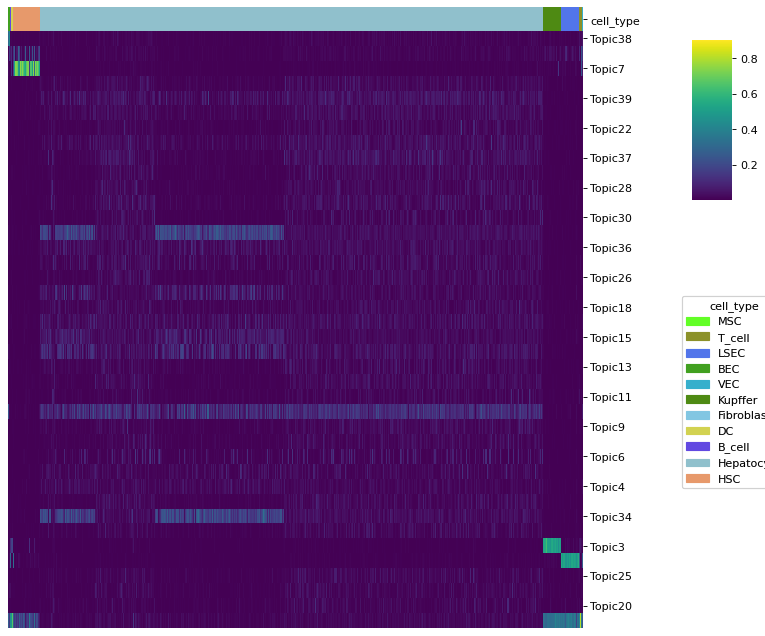

In [12]:
cell_topic_heatmap(cistopic_obj, variables=["cell_type"], scale=False, legend_loc_x=1.05, legend_loc_y=-1.2,
                   legend_dist_y=-1, figsize=(10, 10))
plt.show()

To find the topics of each cell type, we average the topic contributions per cell type and take, for each topic, the cell type where it is highest:

In [13]:
cell_topic = model.cell_topic.T  # cells x topics
cell_topic.index = cistopic_obj.cell_names
# mean topic contribution per cell type (rows: cell types, columns: topics)
mean_per_type = cell_topic.groupby(cd.loc[cell_topic.index, "cell_type"]).mean()
specificity = mean_per_type / mean_per_type.sum()  # fraction of each topic's mean per cell type
best = pd.DataFrame({"cell_type": specificity.idxmax(), "fraction": specificity.max().round(2)})
best.sort_values(["cell_type", "fraction"], ascending=[True, False])

,cell_type,fraction
Topic38,BEC,0.69
Topic17,Fibroblast,0.20
Topic7,HSC,0.43
Topic14,Hepatocyte,0.45
Topic39,Hepatocyte,0.44
Topic10,Hepatocyte,0.43
Topic33,Hepatocyte,0.43
Topic16,Hepatocyte,0.42
Topic6,Hepatocyte,0.40
Topic34,Hepatocyte,0.40


### Zonation topics

Which topics follow hepatocyte zonation? We take the hepatocytes only, compute the mean contribution of every topic in PP, mid and PC hepatocytes, and look for the topics with the largest PC / PP ratio (pericentral) and the smallest (periportal). Then we plot the top periportal and pericentral topic on the UMAP:

most periportal topics:
zone        PP    mid     PC  PC/PP
Topic14  0.067  0.031  0.014  0.217
Topic13  0.027  0.009  0.006  0.231
Topic5   0.028  0.009  0.008  0.277
most pericentral topics:
zone        PP    mid     PC   PC/PP
Topic30  0.008  0.012  0.036   4.617
Topic33  0.011  0.038  0.052   4.646
Topic6   0.005  0.016  0.073  14.452


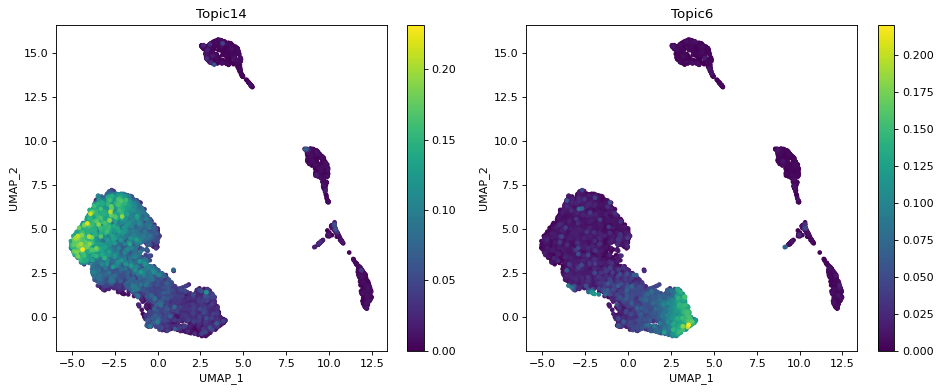

In [14]:
# hepatocytes with a zone label, and the mean contribution of every topic per zone (topics as rows)
hep = cd.index[cd["zone"].isin(["PP", "mid", "PC"])]
mean_per_zone = cell_topic.loc[hep].groupby(cd.loc[hep, "zone"]).mean().T[["PP", "mid", "PC"]]
mean_per_zone["PC/PP"] = mean_per_zone["PC"] / mean_per_zone["PP"]
zonation_topics = mean_per_zone.sort_values("PC/PP")
print("most periportal topics:"); print(zonation_topics.head(3).round(3))
print("most pericentral topics:"); print(zonation_topics.tail(3).round(3))

# topic numbers of the most periportal (lowest ratio) and most pericentral (highest ratio) topic
top_pp = int(zonation_topics.index[0].removeprefix("Topic"))
top_pc = int(zonation_topics.index[-1].removeprefix("Topic"))
plot_topic(cistopic_obj, reduction_name="UMAP_harmony", selected_topics=[top_pp, top_pc], num_columns=2, figsize=(12, 5))
plt.show()

Some topics clearly follow zonation. Topic14 is about five times more active in periportal than in pericentral hepatocytes, and Topic6 about fourteen times more active in pericentral ones; on the UMAP they light up at the two ends of the hepatocyte cluster, and not in the other cell types. These topics are sets of co-accessible regions: candidate periportal and pericentral enhancers.

### The regions of a topic

Each topic is a distribution over regions. To get a set of regions per topic, pycisTopic **binarises** the topic-region scores: Otsu's method picks the threshold that best separates high and low scores. These region sets can be used for motif enrichment (which transcription factors drive this topic?) or for gene set analysis of nearby genes.

In [17]:
# a dict: topic name -> table of the regions above the Otsu threshold
region_sets = binarize_topics(cistopic_obj, method="otsu", plot=False)
plt.close("all")  # binarize_topics leaves empty figures open
pd.Series({topic: len(regions) for topic, regions in region_sets.items()}, name="regions").describe().round(0)

count       40.0
mean     12239.0
std       1565.0
min       8185.0
25%      11288.0
50%      12124.0
75%      13427.0
max      14822.0
Name: regions, dtype: float64

We save the region sets of the zonation topics as BED files (load them in IGV next to *Cyp2e1* or *Glul*), and the cisTopic object for part 4.

In [18]:
os.makedirs("topic_regions", exist_ok=True)
for topic in [f"Topic{top_pp}", f"Topic{top_pc}"]:
    # region names "chr:start-end" -> three BED columns
    regions = region_sets[topic].index.str.extract(r"(.+):(\d+)-(\d+)")
    regions.to_csv(f"topic_regions/{topic}.bed", sep="\t", header=False, index=False)
with open("cistopic_obj.pkl", "wb") as f:
    pickle.dump(cistopic_obj, f)
print(os.listdir("topic_regions"), f"cistopic_obj.pkl: {os.path.getsize('cistopic_obj.pkl') / 1e6:.0f} MB")

['Topic6.bed', 'Topic14.bed'] cistopic_obj.pkl: 1205 MB


## Summary

- Topic modelling turns the sparse cell × region matrix into a dense **cell × topic** matrix (for UMAP and clustering) and a **topic × region** matrix (which regions define each cell state).
- The number of topics is chosen by comparing models; the cell-type and zonation structure should be visible.
- **Batch effects** between samples are corrected on the topic level with Harmony.
- Clusters found from ATAC alone separate every major cell type. The ARI with the RNA labels is nevertheless low, because the hepatocytes are split into several clusters, which follow **zonation** rather than noise.
- Topics are region sets: some mark cell types, others follow the pericentral-periportal axis (here Topic14 periportal, Topic6 pericentral).

In [part 3](part_3_snapatac2.ipynb) we analyse the same cells with SnapATAC2, and in [part 4](part_4_dars.ipynb) we find differentially accessible regions with both tools.

## Exercises

1. Repeat the clustering and the ARI with the model of 30 or 50 topics instead of 40 (`evaluate_models(models, select_model=30, return_model=True, plot=False)`, then `cistopic_obj.add_LDA_model(...)` and Step 3 again). Do the cell types and the zonation topics change?
2. Which topics are specific to Kupffer cells or to stellate cells (see the table of Step 4)? Plot them on the UMAP with `plot_topic`.
3. Skip the Harmony correction: cluster on the uncorrected topics (`harmony=False`) and compute the ARI with the cell types and with the mouse (`cd["mouse"]`). What does the batch effect do to the clusters?